<a href="https://colab.research.google.com/github/vbuxbaum/bingo-api/blob/main/Curso_Teo_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Arvore de decisão

## Exemplo frutas

In [ ]:
import pandas as pd

df = pd.read_excel("data/dados_frutas.xlsx")
df

In [ ]:
from rich import print
from sklearn import tree

tree_algo = tree.DecisionTreeClassifier()

y = df["Fruta"]
attributes = df.columns.drop("Fruta")
print(attributes.to_list())
x = df[attributes]

# Aqui tem ML acontecendo
tree_algo.fit(x, y)

print(tree_algo.predict([[1, 0, 0, 1]]))

In [ ]:
import matplotlib.pyplot as plt

plt.figure(dpi=400)

tree.plot_tree(tree_algo, feature_names=attributes, class_names=tree_algo.classes_, filled=True)

In [ ]:
proba = tree_algo.predict_proba([[0, 1, 0, 1]])[0]
pd.Series(proba, index=tree_algo.classes_)

## Exemplo Cervejas

In [ ]:
import pandas as pd

df = pd.read_excel("data/dados_cerveja.xlsx")
df.head()

,id,temperatura,copo,espuma,cor,classe
0,1,-5,mud,não,escura,weissbier
1,2,-5,mud,sim,escura,weissbier
2,3,-1,pint,não,clara,weissbier
3,4,-1,pint,sim,clara,weissbier
4,5,-5,pint,não,escura,pale-ale


In [ ]:
features = df.columns.drop(["classe",'id'])
target = 'classe'
features

Index(['temperatura', 'copo', 'espuma', 'cor'], dtype='object')

In [ ]:
from sklearn import tree

model = tree.DecisionTreeClassifier()

x = df[features]
y = df[target]

# o fit não funciona diretamente porque algumas features não são numericas
# então precisamos fazer esses replaces (pandas seu lindo)
x = x.replace({'mud': 1, 'pint': 2, "sim": 1, 'não': 0, 'clara': 0, 'escura': 1})

model.fit(x, y)

/tmp/ipython-input-12-1508238441.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x = x.replace({'mud': 1, 'pint': 2, "sim": 1, 'não': 0, 'clara': 0, 'escura': 1})


DecisionTreeClassifier()

[Text(0.5555555555555556, 0.875, 'copo <= 1.5\ngini = 0.653\nsamples = 12\nvalue = [3, 5, 4]\nclass = pilsen'),
 Text(0.3333333333333333, 0.625, 'temperatura <= -3.0\ngini = 0.408\nsamples = 7\nvalue = [0, 5, 2]\nclass = pilsen'),
 Text(0.4444444444444444, 0.75, 'True  '),
 Text(0.2222222222222222, 0.375, 'cor <= 0.5\ngini = 0.444\nsamples = 3\nvalue = [0, 1, 2]\nclass = weissbier'),
 Text(0.1111111111111111, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [0, 1, 0]\nclass = pilsen'),
 Text(0.3333333333333333, 0.125, 'gini = 0.0\nsamples = 2\nvalue = [0, 0, 2]\nclass = weissbier'),
 Text(0.4444444444444444, 0.375, 'gini = 0.0\nsamples = 4\nvalue = [0, 4, 0]\nclass = pilsen'),
 Text(0.7777777777777778, 0.625, 'temperatura <= -3.0\ngini = 0.48\nsamples = 5\nvalue = [3, 0, 2]\nclass = pale-ale'),
 Text(0.6666666666666667, 0.75, '  False'),
 Text(0.6666666666666666, 0.375, 'gini = 0.0\nsamples = 3\nvalue = [3, 0, 0]\nclass = pale-ale'),
 Text(0.8888888888888888, 0.375, 'gini = 0.0\nsamples = 2\nv

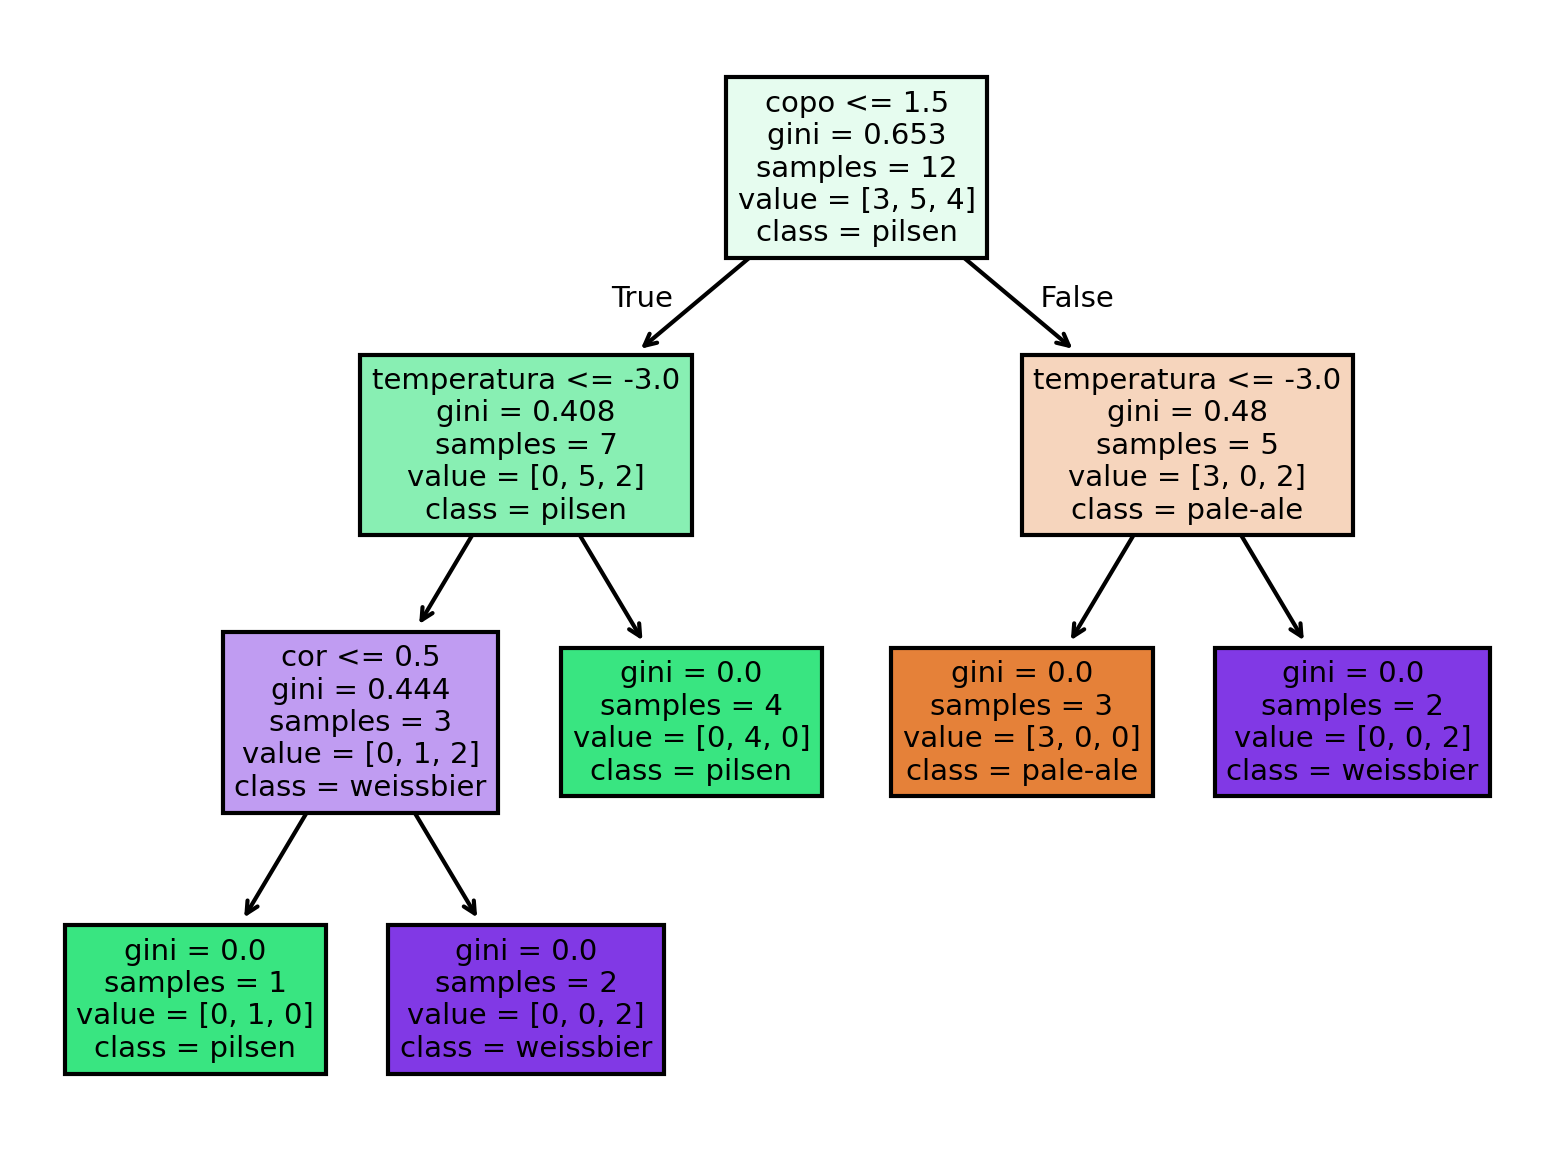

In [ ]:
import matplotlib.pyplot as plt

plt.figure(dpi=300)

tree.plot_tree(model, feature_names=features, class_names=model.classes_, filled=True)

In [ ]:
proba = model.predict_proba([[2, 0, 0, -5]])[0]
print(sorted(features))
pd.Series(proba, index=model.classes_)

['copo', 'cor', 'espuma', 'temperatura']


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


,0
pale-ale,0.0
pilsen,1.0
weissbier,0.0


## Case Star Wars

In [2]:
import pandas as pd

df = pd.read_parquet("/content/data/dados_clones.parquet")
df.columns


Index(['p2o_master_id', 'Massa(em kilos)', 'General Jedi encarregado',
       'Estatura(cm)', 'Distância Ombro a ombro', 'Tamanho do crânio',
       'Tamanho dos pés', 'Tempo de existência(em meses)', 'Status '],
      dtype='object')

/tmp/ipython-input-3-3926508029.py:18: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x = x.replace(


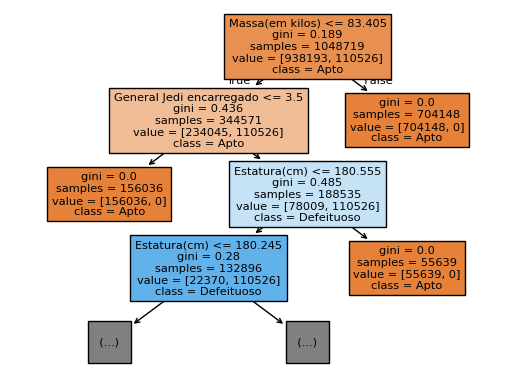

In [3]:
from sklearn import tree
from enum import Enum, auto
sw_model = tree.DecisionTreeClassifier()

target = "Status "
features = ["Estatura(cm)", "Massa(em kilos)", "General Jedi encarregado"]

x = df[features]
y = df[target]

class General(Enum):
    Aayla = auto()
    Mace = auto()
    Obi_wan = auto()
    ShaakTi = auto()
    Yoda = auto()

x = x.replace(
    {
    "Yoda": General.Yoda.value, "Shaak Ti": General.ShaakTi.value,
    "Obi-Wan Kenobi": General.Obi_wan.value, "Mace Windu": General.Mace.value,
    "Aayla Secura": General.Aayla.value
    }
)

sw_model.fit(x, y)
plt_tree = tree.plot_tree(sw_model, feature_names=features, class_names=sw_model.classes_, filled=True, max_depth=3)

## Anotações

Modelos de regressão = estimativa de um valor numérico. Exemplos:

- Quantidade de vendas
- Receita presumida
- Precificação de imóvel
- Volume de chuva

Modelos de classificação = estimativa de um rótulo/classe. Exemplos:

- É potencial comprador, ou não?
- É potencial churn, ou não?
- A face reconhecida é da pessoa X?
- O diagnóstico é de cancer, ou não? Qual tipo?
- **Obs:** é sempre sobre se encaixar em uma (ou mais) rótulos, ou não.

## Regressão

### Ideia do calculo

`Y = a + b * X`

Forma de encontrar o `a` e `b`: método dos mínimos quadrados
> Outras opções: máxima verossimilhança, ou método bayesiano

Erro = `y - y'`
(para cada ponto, a diferença do valor real para sua projeção/estimativa na reta proposta)

Erro quadrático = `(y - y')^2`

Soma do erro quadrático = ∑`(y - y')^2` = ∑`(y - (a + b * X))^2`

Ao minimizarmos (derivada igual a zero) esse somatório, encontramos os valores ideais de `a` e `b`

Se tivermos mais variáveis influenciando, a formula fica: `Y = a + b1 * X1 + b2 * X2 + b3 * X3 ...`




In [3]:
import pandas as pd

df = pd.read_excel("/content/data/dados_cerveja_nota.xlsx")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       15 non-null     int64  
 1   cerveja  15 non-null     int64  
 2   nota     15 non-null     float64
dtypes: float64(1), int64(2)
memory usage: 492.0 bytes


In [4]:
from sklearn import linear_model, tree

X = df[['cerveja']]  # X maiusculo para representar que é uma matriz
y = df['nota']  # valor que quero descobrir, ou seja, qual a nota a pessoa terá

regression = linear_model.LinearRegression()
regression.fit(X, y)


LinearRegression()

In [5]:
a, b = regression.intercept_, regression.coef_[0]
print(a,b)

0.151612903225808 1.0362903225806448


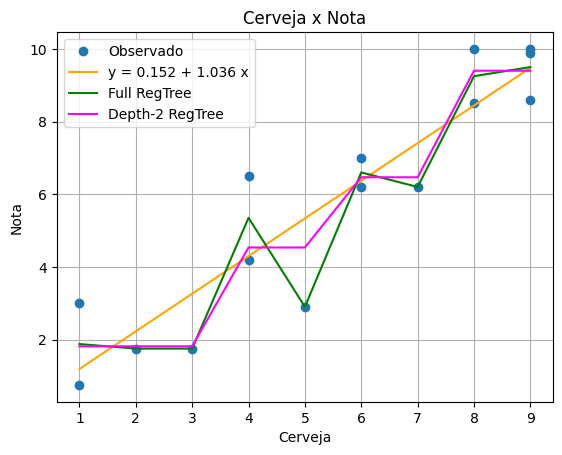

In [9]:
predict_reg = regression.predict(X.drop_duplicates())

full_tree = tree.DecisionTreeRegressor(random_state=42)
full_tree.fit(X, y)
predict_full_tree = full_tree.predict(X.drop_duplicates())


d2_tree = tree.DecisionTreeRegressor(random_state=42, max_depth=2)
d2_tree.fit(X, y)
predict_d2_tree = d2_tree.predict(X.drop_duplicates())


import matplotlib.pyplot as plt

plt.plot(X['cerveja'], y, 'o')
plt.plot(X.drop_duplicates()['cerveja'], predict_reg, color='orange')
plt.plot(X.drop_duplicates()['cerveja'], predict_full_tree, color='green')
plt.plot(X.drop_duplicates()['cerveja'], predict_d2_tree, color='magenta')
plt.grid(True)
plt.title("Cerveja x Nota")
plt.xlabel("Cerveja")
plt.ylabel("Nota")
plt.legend(["Observado",
            f"y = {a:.3f} + {b:.3f} x",
            "Full RegTree",
            "Depth-2 RegTree"])


## Modelos de classificação

###